# WorkflowHub edges vs. citation-order edges

Compare ordered tool co-citations with tool pairs in Galaxy workflows

- **Workflows:** `data/biotools/biotools_edges.csv` (`map_galaxy_tools.py`): tool A feeds tool B in `n_workflows` workflows
- **Citations:** `../edges-processed/directed_edges.csv` (`citation-order/` steps 3 to 5): tool A is cited before tool B in `n_articles` articles

Each workflow pair is put in its main workflow direction, `source` → `target`. Then both sources get a direction ratio, from 0 to 1: the share of the counts that go `source` → `target`.

`distance = |wf_dir - cit_dir|` says how well the two agree: 0 = the same ratio, 1 = opposite directions (all workflows one way, all articles the other).

In [164]:
import duckdb

MAX_CONFIDENCE = 3   # workflow edges to use: 1 = Codex mapping only, 2 = + name match, 3 = all (+ prefix match)
MIN_ARTICLES = 1    # pairs with fewer articles are left out of the summary

con = duckdb.connect()
con.execute(f"""
    CREATE OR REPLACE TABLE wf AS
    SELECT lower(source) AS source, lower(target) AS target, n_workflows, confidence
    FROM 'data/biotools/biotools_edges.csv' WHERE confidence <= {MAX_CONFIDENCE}
""")
con.execute("CREATE OR REPLACE TABLE cit AS SELECT source, target, n_articles FROM '../edges-processed/directed_edges.csv'")
con.execute("CREATE OR REPLACE TABLE cit_tools AS SELECT source AS tool FROM cit UNION SELECT target FROM cit")

# One row per workflow pair in its main direction, with the counts of both sources both ways.
con.execute(f"""
    CREATE OR REPLACE TABLE pairs AS
    WITH counts AS (
        SELECT f.source, f.target,
               f.n_workflows AS wf_fwd, coalesce(r.n_workflows, 0) AS wf_rev,
               coalesce(cf.n_articles, 0) AS cit_fwd, coalesce(cr.n_articles, 0) AS cit_rev,
               greatest(f.confidence, coalesce(r.confidence, f.confidence)) AS confidence,  -- the weaker of both directions
               f.source IN (SELECT tool FROM cit_tools) AND f.target IN (SELECT tool FROM cit_tools) AS both_in_cit
        FROM wf f
        LEFT JOIN wf r ON r.source = f.target AND r.target = f.source
        LEFT JOIN cit cf ON cf.source = f.source AND cf.target = f.target
        LEFT JOIN cit cr ON cr.source = f.target AND cr.target = f.source
        WHERE f.n_workflows > coalesce(r.n_workflows, 0)                -- the main direction,
           OR (f.n_workflows = r.n_workflows AND f.source < f.target)  -- on a tie the alphabetical one
    ),
    ratios AS (
        SELECT *,
               wf_fwd / (wf_fwd + wf_rev) AS wf_dir,
               cit_fwd / nullif(cit_fwd + cit_rev, 0) AS cit_dir
        FROM counts
    )
    SELECT *, wf_dir - cit_dir AS distance FROM ratios
""")

## Print edges

One row per workflow pair, ordered by number of occurances in workflows.

In [165]:
con.sql("""
    SELECT source, target, wf_fwd, wf_rev, round(wf_dir, 2) AS wf_dir,
           cit_fwd, cit_rev, round(cit_dir, 2) AS cit_dir, round(distance, 2) AS distance
    FROM pairs ORDER BY wf_fwd + wf_rev DESC, cit_fwd + cit_rev DESC
""").show(max_rows=1000)

┌───────────────────────────────┬───────────────────────────────┬────────┬────────┬────────┬─────────┬─────────┬─────────┬──────────┐
│            source             │            target             │ wf_fwd │ wf_rev │ wf_dir │ cit_fwd │ cit_rev │ cit_dir │ distance │
│            varchar            │            varchar            │ int64  │ int64  │ double │  int64  │  int64  │ double  │  double  │
├───────────────────────────────┼───────────────────────────────┼────────┼────────┼────────┼─────────┼─────────┼─────────┼──────────┤
│ anndata                       │ scanpy                        │     24 │     24 │    0.5 │       6 │       2 │    0.75 │    -0.25 │
│ fastqc                        │ multiqc                       │     41 │      0 │    1.0 │       0 │       0 │    NULL │     NULL │
│ fastp                         │ multiqc                       │     37 │      0 │    1.0 │      36 │      18 │    0.67 │     0.33 │
│ fastp                         │ bwa                         

## Statistics

Comparison of tool pairs in co-citation graph and in Galaxy workflows.


In [166]:
# The same statistics for pairs co-cited in at least 1, 5, 10 or 20 articles.
con.sql("""
    SELECT min_articles,
           count(*)                    AS pairs_compared,
           round(avg(distance), 2)     AS mean_distance,
           round(median(distance), 2)  AS median_distance
    FROM pairs, (VALUES (1), (5), (10), (20), (50), (100), (200)) v(min_articles)
    WHERE cit_fwd + cit_rev >= min_articles
    GROUP BY min_articles ORDER BY min_articles
""").show()

┌──────────────┬────────────────┬───────────────┬─────────────────┐
│ min_articles │ pairs_compared │ mean_distance │ median_distance │
│    int32     │     int64      │    double     │     double      │
├──────────────┼────────────────┼───────────────┼─────────────────┤
│            1 │            264 │          0.31 │             0.2 │
│            5 │            186 │          0.29 │            0.22 │
│           10 │            141 │           0.3 │            0.21 │
│           20 │            100 │          0.27 │            0.16 │
│           50 │             68 │          0.25 │            0.15 │
│          100 │             45 │          0.25 │            0.14 │
│          200 │             25 │          0.16 │            0.11 │
└──────────────┴────────────────┴───────────────┴─────────────────┘



In [167]:
# The same statistics for pairs co-cited in at least 1, 5, 10 or 20 articles.
con.sql("""
    SELECT min_articles,
           count(*)                    AS pairs_compared,
           round(avg(distance), 2)     AS mean_distance,
           round(median(distance), 2)  AS median_distance
    FROM pairs, (VALUES (1), (5), (10), (20), (50), (100), (200)) v(min_articles)
    WHERE cit_fwd + cit_rev >= min_articles and wf_fwd + wf_rev >= 2
    GROUP BY min_articles ORDER BY min_articles
""").show()

┌──────────────┬────────────────┬───────────────┬─────────────────┐
│ min_articles │ pairs_compared │ mean_distance │ median_distance │
│    int32     │     int64      │    double     │     double      │
├──────────────┼────────────────┼───────────────┼─────────────────┤
│            1 │            155 │          0.28 │            0.18 │
│            5 │            113 │          0.26 │            0.21 │
│           10 │             83 │          0.27 │            0.18 │
│           20 │             59 │          0.25 │            0.16 │
│           50 │             41 │          0.22 │            0.15 │
│          100 │             26 │          0.22 │            0.15 │
│          200 │             14 │          0.12 │             0.1 │
└──────────────┴────────────────┴───────────────┴─────────────────┘



In [ ]:
# The same statistics, only for pairs in at least 2 workflows and with confidence 1 (Codex mapping).
con.sql("""
    SELECT min_articles,
           count(*)                    AS pairs_compared,
           round(avg(distance), 2)     AS mean_distance,
           round(median(distance), 2)  AS median_distance
    FROM pairs, (VALUES (1), (5), (10), (20), (50), (100), (200)) v(min_articles)
    WHERE cit_fwd + cit_rev >= min_articles and confidence = 1
    GROUP BY min_articles ORDER BY min_articles
""").show()

┌──────────────┬────────────────┬───────────────┬─────────────────┐
│ min_articles │ pairs_compared │ mean_distance │ median_distance │
│    int32     │     int64      │    double     │     double      │
├──────────────┼────────────────┼───────────────┼─────────────────┤
│            1 │            149 │          0.27 │            0.16 │
│            5 │            107 │          0.27 │            0.18 │
│           10 │             83 │          0.28 │             0.2 │
│           20 │             55 │          0.24 │            0.14 │
│           50 │             37 │          0.19 │            0.13 │
│          100 │             23 │          0.22 │            0.13 │
│          200 │             13 │          0.15 │            0.11 │
└──────────────┴────────────────┴───────────────┴─────────────────┘



In [169]:
# Count of pairs with at least 2 workflows
con.execute("SELECT count(*) FROM pairs WHERE wf_fwd + wf_rev >= 2",
                       ).fetchall()


[(372,)]

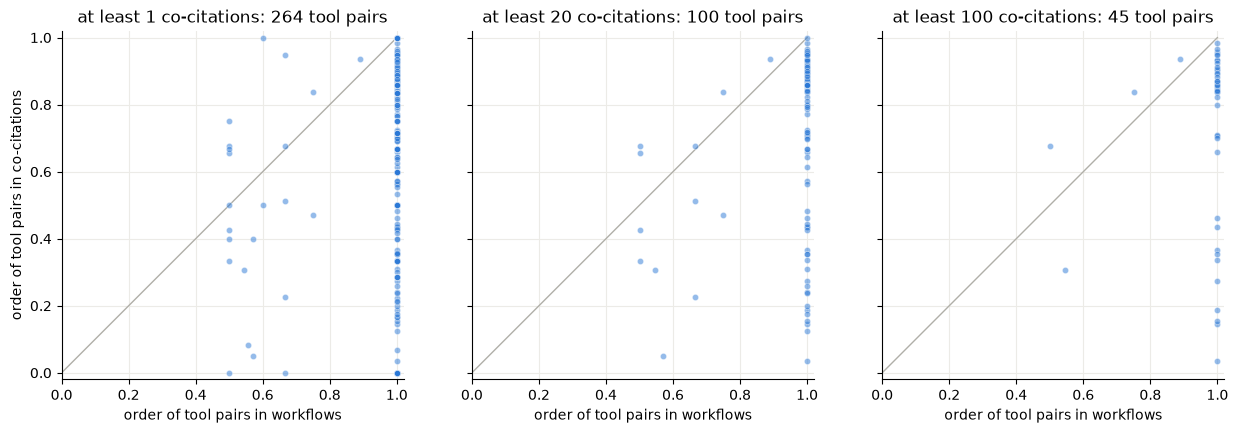

In [170]:
# Workflow direction vs. citation direction, one dot per pair, for pairs with at least 1, 20 and 100 articles.
# On the diagonal both sources have the same ratio.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
for ax, min_articles in zip(axes, [1, 20, 100]):
    rows = con.execute("SELECT wf_dir, cit_dir FROM pairs WHERE cit_fwd + cit_rev >= ?", [min_articles]).fetchall()
    x, y = zip(*rows)
    ax.plot([0, 1], [0, 1], color="#b0afa8", linewidth=1, zorder=1)
    ax.scatter(x, y, s=20, color="#2a78d6", alpha=0.5, edgecolor="white", linewidth=0.5, zorder=2)
    ax.set(xlim=(0, 1.02), ylim=(-0.02, 1.02), aspect="equal",
           xlabel="order of tool pairs in workflows",
           title=f"at least {min_articles} co-citations: {len(rows)} tool pairs")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#ecebe7", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("order of tool pairs in co-citations")
plt.show()

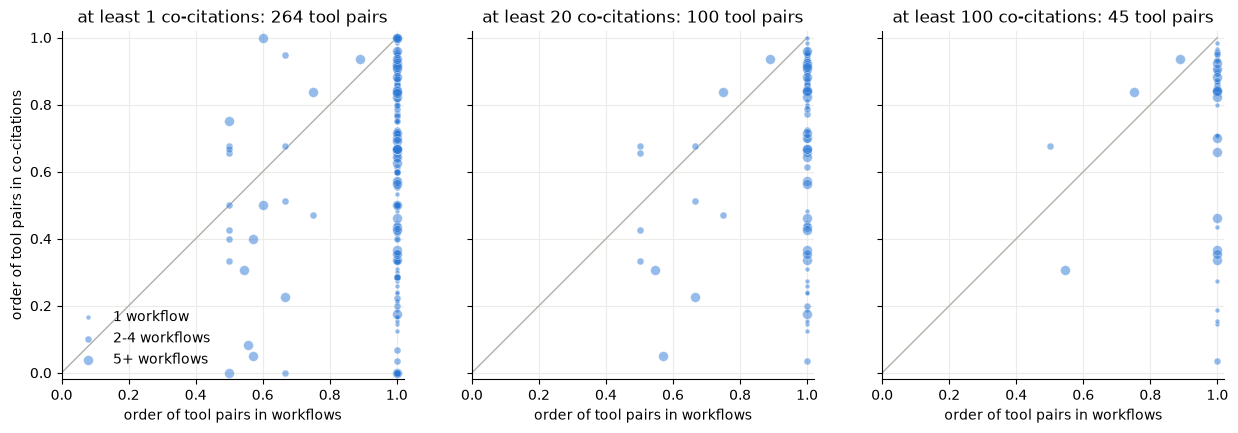

In [171]:
# Workflow direction vs. citation direction, one dot per pair, for pairs with at least 1, 20 and 100 articles.
# Dot size: number of workflows with the pair (1, 2 to 4, 5 or more). On the diagonal both sources have the same ratio.
import matplotlib.pyplot as plt

SIZES = [("1 workflow", 1, 2, 12), ("2-4 workflows", 2, 5, 25), ("5+ workflows", 5, 10**9, 50)]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
for ax, min_articles in zip(axes, [1, 20, 100]):
    rows = con.execute("SELECT wf_dir, cit_dir, wf_fwd + wf_rev FROM pairs WHERE cit_fwd + cit_rev >= ?",
                       [min_articles]).fetchall()
    ax.plot([0, 1], [0, 1], color="#b0afa8", linewidth=1, zorder=1)
    for label, low, high, size in SIZES:
        pts = [(x, y) for x, y, n in rows if low <= n < high]
        if pts:
            ax.scatter(*zip(*pts), s=size, color="#2a78d6", alpha=0.5, edgecolor="white", linewidth=0.5,
                       zorder=2, label=label)
    ax.set(xlim=(0, 1.02), ylim=(-0.02, 1.02), aspect="equal",
           xlabel="order of tool pairs in workflows",
           title=f"at least {min_articles} co-citations: {len(rows)} tool pairs")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#ecebe7", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("order of tool pairs in co-citations")
axes[0].legend(loc="lower left", frameon=False)
plt.show()

## Used edges statistics

How many workflow pairs could be in the citation graph (both tools are in it somewhere), and how many are.

In [172]:
con.sql("""
    UNPIVOT (
        SELECT count(*)                                         AS "workflow pairs",
               count(*) FILTER (both_in_cit)                    AS "both tools in the citation graph",
               count(*) FILTER (cit_dir IS NOT NULL)            AS "also a citation edge",
               count(*) FILTER (cit_fwd + cit_rev >= 5)         AS "citation edge, at least 5 articles",
               count(*) FILTER (cit_fwd + cit_rev >= 10)        AS "citation edge, at least 10 articles",
               count(*) FILTER (cit_fwd + cit_rev >= 20)        AS "citation edge, at least 20 articles"
        FROM pairs
    ) ON COLUMNS(*) INTO NAME measure VALUE pairs
""").show()

┌─────────────────────────────────────┬───────┐
│               measure               │ pairs │
│               varchar               │ int64 │
├─────────────────────────────────────┼───────┤
│ workflow pairs                      │   712 │
│ both tools in the citation graph    │   339 │
│ also a citation edge                │   264 │
│ citation edge, at least 5 articles  │   186 │
│ citation edge, at least 10 articles │   141 │
│ citation edge, at least 20 articles │   100 │
└─────────────────────────────────────┴───────┘

